In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.deterministic import DeterministicProcess
from xgboost import XGBRegressor

# Pembuatan data sintetik: Penjualan dengan Tren Linear dan Musiman Bulanan
waktu = pd.date_range("2010-01-01", "2019-12-31", freq="M")
tren_asli = np.linspace(100, 500, len(waktu))
musiman_asli = np.sin(np.arange(len(waktu)) * (2 * np.pi / 12)) * 50
penjualan = tren_asli + musiman_asli + np.random.normal(0, 10, len(waktu))

df = pd.DataFrame({'Sales': penjualan}, index=waktu)

# Pemisahan Data (Train/Test)
train_size = int(len(df) * 0.8)
df_train, df_test = df.iloc[:train_size].copy(), df.iloc[train_size:].copy()

/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_10536/2263873024.py:9: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  waktu = pd.date_range("2010-01-01", "2019-12-31", freq="M")


In [2]:
# Fitur untuk Regresi Linear (Model 1): Time Dummy (Tren Orde 1)
dp = DeterministicProcess(index=df.index, order=1, constant=True)
X_trend_full = dp.in_sample()

X_train_1 = X_trend_full.iloc[:train_size]
X_test_1 = X_trend_full.iloc[train_size:]

# Target
y_train = df_train['Sales']
y_test = df_test['Sales']

# Fitur untuk XGBoost (Model 2): Bulan
X_train_2 = pd.DataFrame({'Month': df_train.index.month}, index=df_train.index)
X_test_2 = pd.DataFrame({'Month': df_test.index.month}, index=df_test.index)

In [3]:
# -------------------------------------------------------------------
# MODEL 1: REGRESI LINEAR (Mempelajari Tren)
# -------------------------------------------------------------------
# Inisialisasi dan pelatih model pertama
model_1 = LinearRegression(fit_intercept=False)
model_1.fit(X_train_1, y_train)

# Prediksi tren pada data latih dan data uji
y_pred_1_train = pd.Series(model_1.predict(X_train_1), index=y_train.index)
y_pred_1_test = pd.Series(model_1.predict(X_test_1), index=y_test.index)

# -------------------------------------------------------------------
# MENGHITUNG RESIDUAL
# -------------------------------------------------------------------
# Menghapus tren dari target aktual untuk mendapatkan residual pada data latih
y_resid_train = y_train - y_pred_1_train

# -------------------------------------------------------------------
# MODEL 2: XGBOOST (Mempelajari Residual/Musiman)
# -------------------------------------------------------------------
# Inisialisasi dan pelatih model kedua pada residual
model_2 = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=0)
model_2.fit(X_train_2, y_resid_train)

# Prediksi residual pada data latih dan data uji
y_pred_2_train = pd.Series(model_2.predict(X_train_2), index=y_train.index)
y_pred_2_test = pd.Series(model_2.predict(X_test_2), index=y_test.index)

# -------------------------------------------------------------------
# PENGGABUNGAN PREDIKSI AKHIR
# -------------------------------------------------------------------
# Menjumlahkan prediksi tren dan prediksi residual
y_pred_final_train = y_pred_1_train + y_pred_2_train
y_pred_final_test = y_pred_1_test + y_pred_2_test

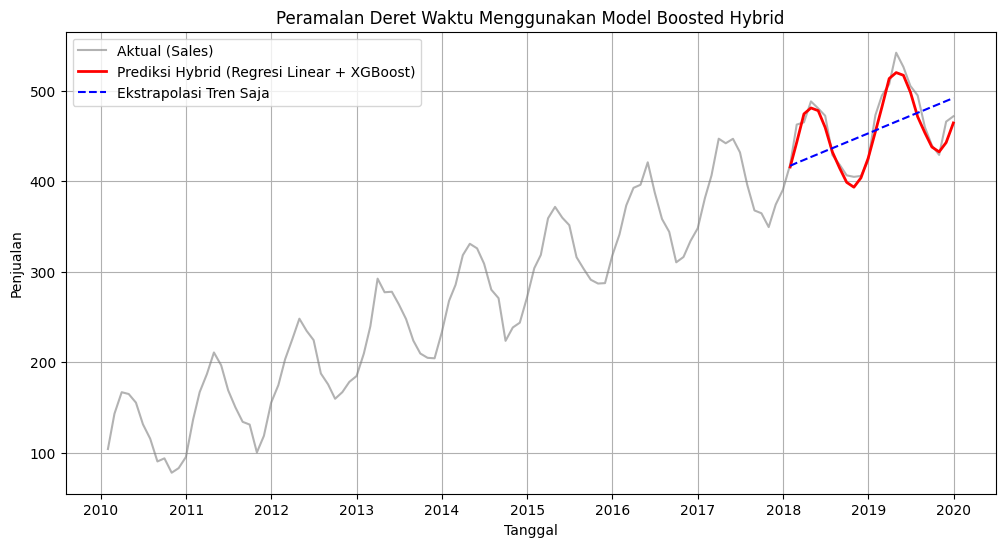

In [4]:
# Visualisasi hasil prediksi
plt.figure(figsize=(12, 6))

# Plot Aktual
plt.plot(df.index, df['Sales'], label='Aktual (Sales)', color='gray', alpha=0.6)

# Plot Prediksi Final pada Data Uji (Test Data)
plt.plot(y_pred_final_test.index, y_pred_final_test, label='Prediksi Hybrid (Regresi Linear + XGBoost)', color='red', linewidth=2)

# Plot Tren Saja (Sebagai Perbandingan)
plt.plot(y_pred_1_test.index, y_pred_1_test, label='Ekstrapolasi Tren Saja', color='blue', linestyle='--')

plt.title("Peramalan Deret Waktu Menggunakan Model Boosted Hybrid")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan")
plt.legend()
plt.grid(True)
plt.show()

Assignment

Mean Absolute Error (Hybrid Model): 23037.55


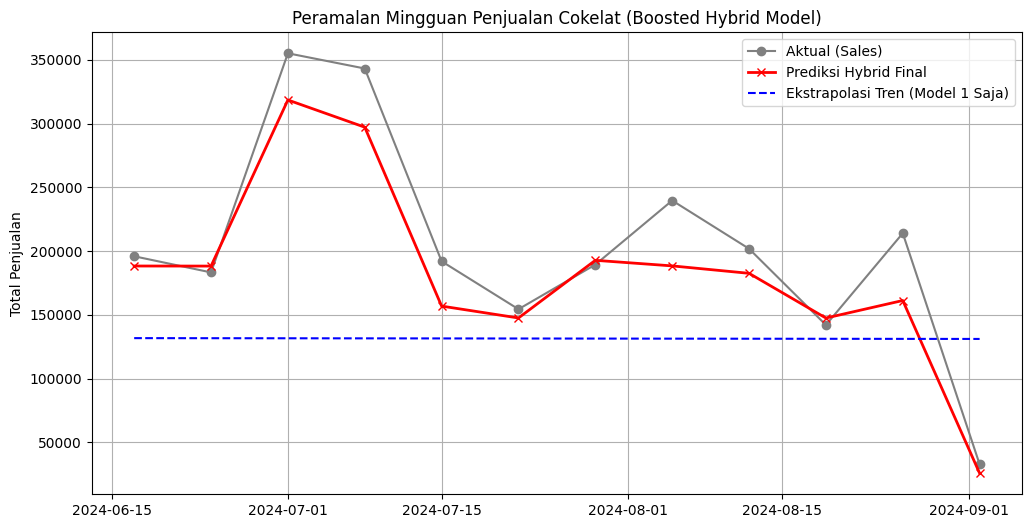

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.deterministic import DeterministicProcess

# ---------------------------------------------
# Bagian 1: Pembersihan & Agregasi Data
# ---------------------------------------------
df = pd.read_csv('chocolate_sales.csv')

# Membersihkan format mata uang
df['Amount_Clean'] = df['Amount'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Agregasi Total Penjualan Mingguan
weekly_sales = df.groupby(pd.Grouper(key='Date', freq='W-MON'))['Amount_Clean'].sum().fillna(0)
weekly_sales.index = weekly_sales.index.to_period('W')

# ---------------------------------------------
# Bagian 2: Rekayasa Fitur
# ---------------------------------------------
# Fitur Tren untuk Model 1
dp = DeterministicProcess(index=weekly_sales.index, order=1, constant=True)
X_trend = dp.in_sample()

# Fitur Musiman untuk Model 2
X_season = pd.DataFrame({
    'Month': weekly_sales.index.month,
    'Week': weekly_sales.index.week
}, index=weekly_sales.index)

# Pemisahan Train/Test (12 Minggu Terakhir)
test_size = 12
y_train = weekly_sales.iloc[:-test_size]
y_test = weekly_sales.iloc[-test_size:]

X_trend_train = X_trend.iloc[:-test_size]
X_trend_test = X_trend.iloc[-test_size:]

X_season_train = X_season.iloc[:-test_size]
X_season_test = X_season.iloc[-test_size:]

# ---------------------------------------------
# Bagian 3: Model 1 - Regresi Linear
# ---------------------------------------------
model_1 = LinearRegression()
model_1.fit(X_trend_train, y_train)

# Menyimpan prediksi tren
y_pred_1_train = pd.Series(model_1.predict(X_trend_train), index=y_train.index)
y_pred_1_test = pd.Series(model_1.predict(X_trend_test), index=y_test.index)

# ---------------------------------------------
# Bagian 4: Menghitung Residual & Model 2 - XGBoost
# ---------------------------------------------
# Residual adalah apa yang tidak berhasil dipelajari oleh Regresi Linear
y_resid_train = y_train - y_pred_1_train

model_2 = XGBRegressor(n_estimators=50, learning_rate=0.1, random_state=42)
model_2.fit(X_season_train, y_resid_train)

# Menyimpan prediksi residual
y_pred_2_test = pd.Series(model_2.predict(X_season_test), index=y_test.index)

# ---------------------------------------------
# Bagian 5: Rekonstruksi Hybrid & Evaluasi
# ---------------------------------------------
# Prediksi Akhir = Prediksi Tren + Prediksi Residual
y_pred_final_test = y_pred_1_test + y_pred_2_test

mae = mean_absolute_error(y_test, y_pred_final_test)
print(f"Mean Absolute Error (Hybrid Model): {mae:.2f}")

# Visualisasi
plt.figure(figsize=(12, 6))
plt.plot(y_test.index.to_timestamp(), y_test, label='Aktual (Sales)', color='gray', marker='o')
plt.plot(y_pred_final_test.index.to_timestamp(), y_pred_final_test, label='Prediksi Hybrid Final', color='red', marker='x', linewidth=2)
plt.plot(y_pred_1_test.index.to_timestamp(), y_pred_1_test, label='Ekstrapolasi Tren (Model 1 Saja)', color='blue', linestyle='--')

plt.title("Peramalan Mingguan Penjualan Cokelat (Boosted Hybrid Model)")
plt.ylabel("Total Penjualan")
plt.legend()
plt.grid(True)
plt.show()